# Day 16 – Model Evaluation Using Titanic Dataset

## Objective
The objective of this project is to evaluate a Logistic Regression classification model using the Titanic dataset.

We will use different evaluation techniques to understand how well our model predicts passenger survival.

### Topics covered
- 5-Fold Cross-Validation
- Confusion Matrix
- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC

In [15]:
import pandas as pd
df = pd.read_csv("train.csv")
print(df.head())
print(df.shape)
print(df.columns)

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
(8

In [4]:
print(df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [8]:
print("Dataset shape:", df.shape)

print("\nSurvival count:")
print(df["Survived"].value_counts())

print("\nSurvival percentage:")
print(df["Survived"].value_counts(normalize=True) * 100)

Dataset shape: (891, 12)

Survival count:
Survived
0    549
1    342
Name: count, dtype: int64

Survival percentage:
Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


In [9]:
# Input features
X = df.drop(
    columns=["Survived", "PassengerId", "Name", "Ticket", "Cabin"]
)

# Target variable
y = df["Survived"]

# Check the results
print("Input shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput columns:")
print(X.columns.tolist())

print("\nTarget:")
print(y.head())

Input shape: (891, 7)
Target shape: (891,)

Input columns:
['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']

Target:
0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64


In [4]:
from sklearn.linear_model import LogisticRegression

# Create the model
model = LogisticRegression(max_iter=1000)

print("Logistic Regression model created successfully!")

Logistic Regression model created successfully!


In [7]:
import pandas as pd

# Load Titanic dataset
df = pd.read_csv("train.csv")

# Check the dataset
print(df.head())
print("Dataset shape:", df.shape)

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
Da

In [8]:
# Input features
X = df.drop(
    columns=["Survived", "PassengerId", "Name", "Ticket", "Cabin"]
)

# Target variable
y = df["Survived"]

# Check the results
print("Input shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput columns:")
print(X.columns.tolist())

print("\nTarget:")
print(y.head())

Input shape: (891, 7)
Target shape: (891,)

Input columns:
['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']

Target:
0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64


In [9]:
# Fill missing Age values with median
X["Age"] = X["Age"].fillna(X["Age"].median())

# Fill missing Embarked values with most common value
X["Embarked"] = X["Embarked"].fillna(X["Embarked"].mode()[0])

# Convert text columns into numerical columns
X = pd.get_dummies(
    X,
    columns=["Sex", "Embarked"],
    drop_first=True,
    dtype=int
)

# Check missing values
print("Missing values:")
print(X.isnull().sum())

print("\nUpdated shape:", X.shape)
print("\nUpdated columns:", X.columns.tolist())

Missing values:
Pclass        0
Age           0
SibSp         0
Parch         0
Fare          0
Sex_male      0
Embarked_Q    0
Embarked_S    0
dtype: int64

Updated shape: (891, 8)

Updated columns: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q', 'Embarked_S']


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

# Create the model
model = LogisticRegression(max_iter=1000)

# Perform 5-fold cross-validation
scores = cross_val_score(model, X, y, cv=5, scoring="accuracy")

# Display results
print("Accuracy for each fold:", scores)
print("Average accuracy:", scores.mean())

Accuracy for each fold: [0.7877095  0.78651685 0.78651685 0.76966292 0.8258427 ]
Average accuracy: 0.7912497646098802


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train the model
model.fit(X_train, y_train)

# Predict survival
y_pred = model.predict(X_test)

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[90 15]
 [19 55]]


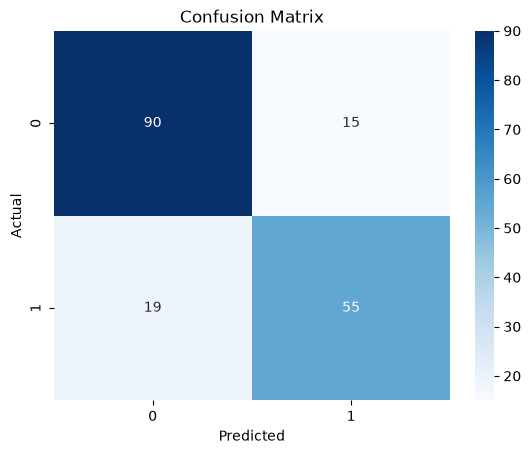

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

# Plot confusion matrix
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

# Add labels
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

# Display plot
plt.show()

In [13]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# Display results
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 0.8100558659217877
Precision: 0.7857142857142857
Recall: 0.7432432432432432
F1 Score: 0.7638888888888888


In [14]:
from sklearn.metrics import roc_auc_score

# Get survival probabilities
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate ROC-AUC
auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", auc)

ROC-AUC Score: 0.8824967824967825
